# 05 · Visualizaciones, reporte e implicaciones

**Objetivo:** Medir con precios reales cuánto sobreprecio sostiene la marca líder frente a su competidor directo, como caso de valor de marca para directores de marketing y ventas.

**Pregunta:** ¿Cómo se comunica el hallazgo y qué hace cada audiencia?

Convenciones: **verde ▲** = Coca-Cola más cara que Pepsi en la misma tienda; **rojo ▼** = más barata;
gris = no distinta de cero; dorado = referencia (mediana o precio de Pepsi).

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import entorno
entorno.setup()
import profeco, tablas, pares, estadistica as E, charts as C
import prima as P
PROC, META, CHARTS, SOCIAL = entorno.PROC, entorno.META, entorno.CHARTS, entorno.SOCIAL
CFG = entorno.config()
reg = entorno.registrar
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
pts, st, cat = P.load()
REPS = 500
import graficas as G, reporte, plantillas, re
res = entorno.cifras()
pl = pd.read_csv(PROC / "pares_lata.csv")
pf = pd.read_csv(PROC / "pares_familiar.csv")
des = pd.read_csv(PROC / "prima_desglose.csv")
tt = pd.read_csv(PROC / "prima_por_comparacion.csv", index_col=0)
lad = pd.read_csv(PROC / "precio_por_litro_presentacion.csv")

## Gráfica principal: prima de la lata en la misma tienda

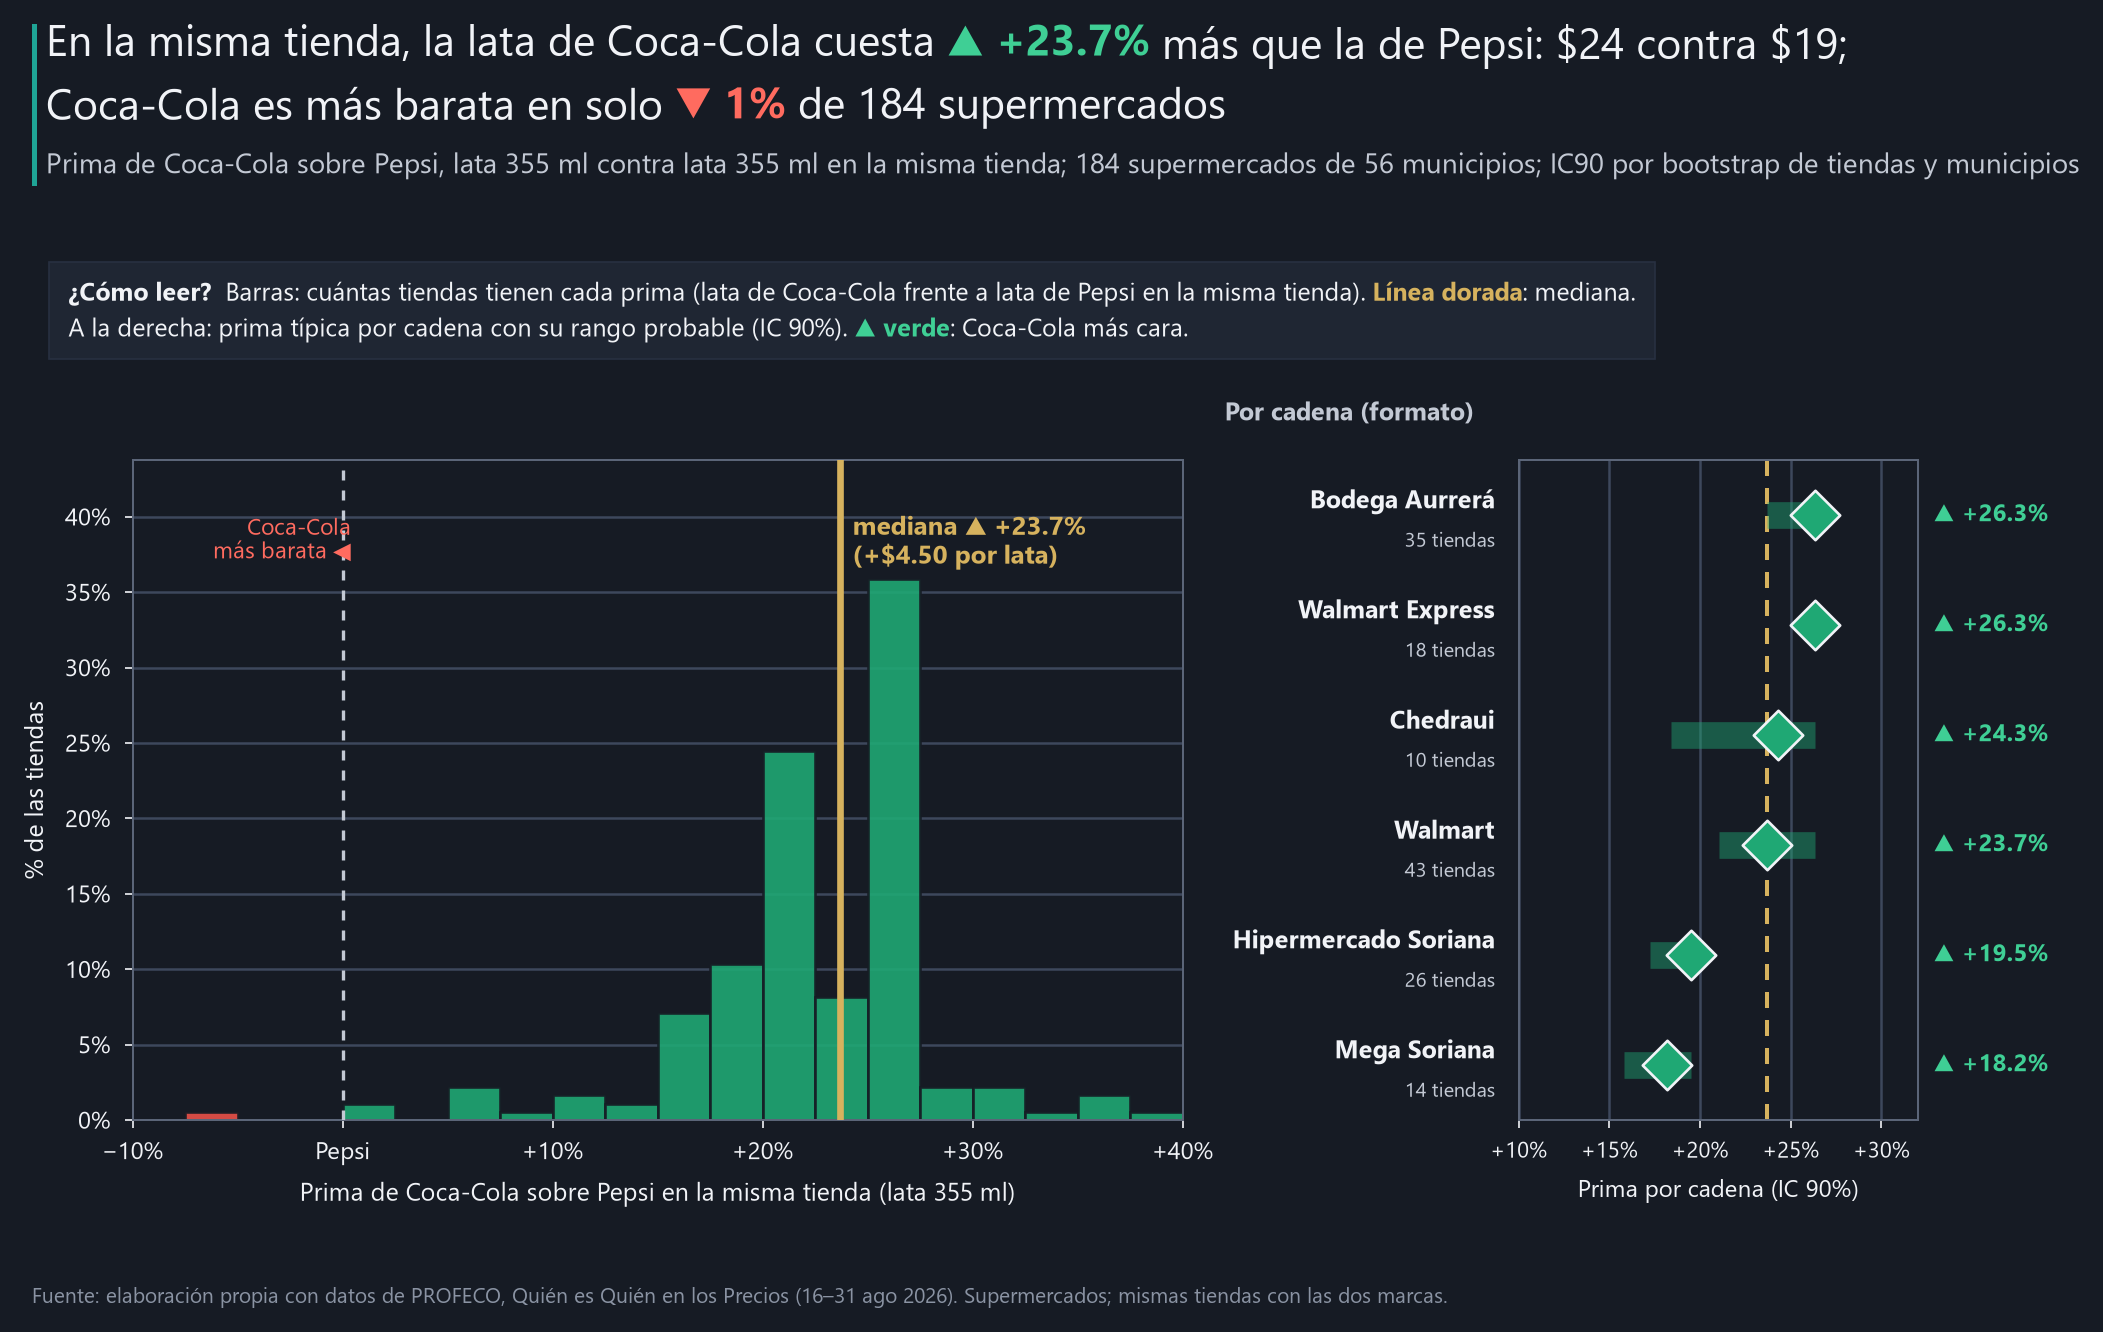

In [2]:
G.premium_main(pl, des, res, CHARTS / "01_prima_lata.png", svg=True); plt.show()

### Versiones para publicar (1280×720 y 1080×1350)

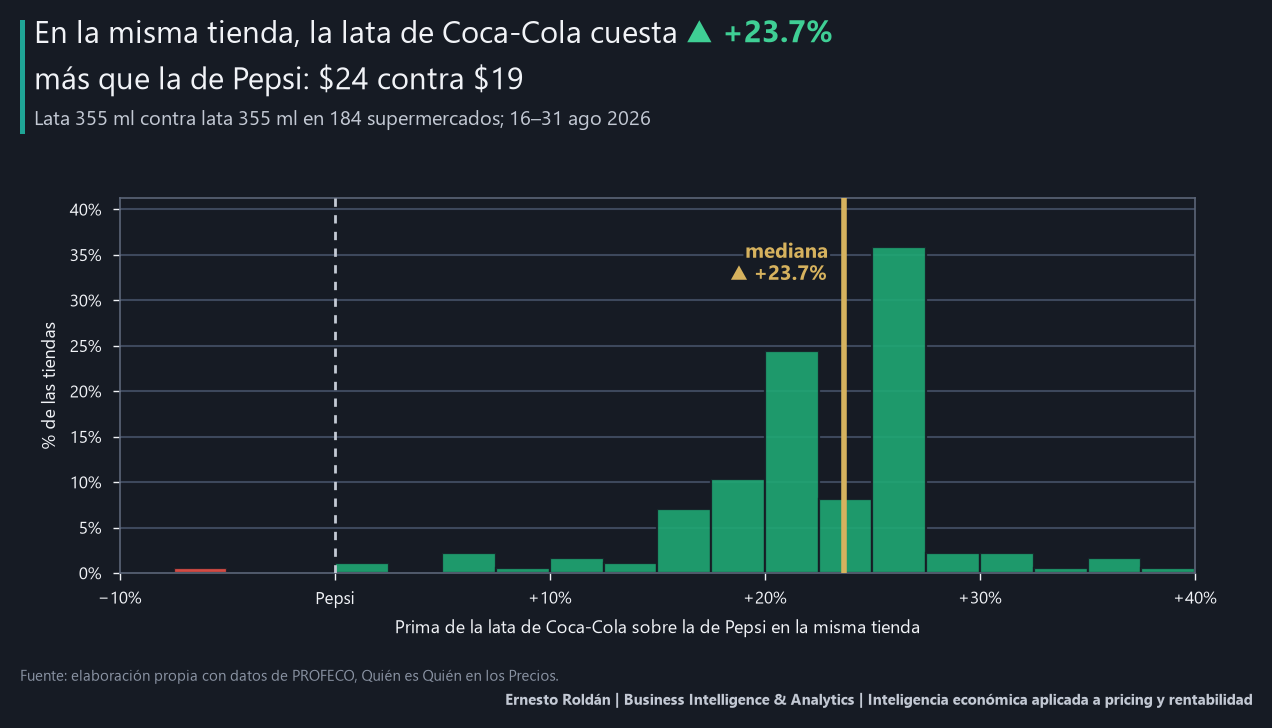

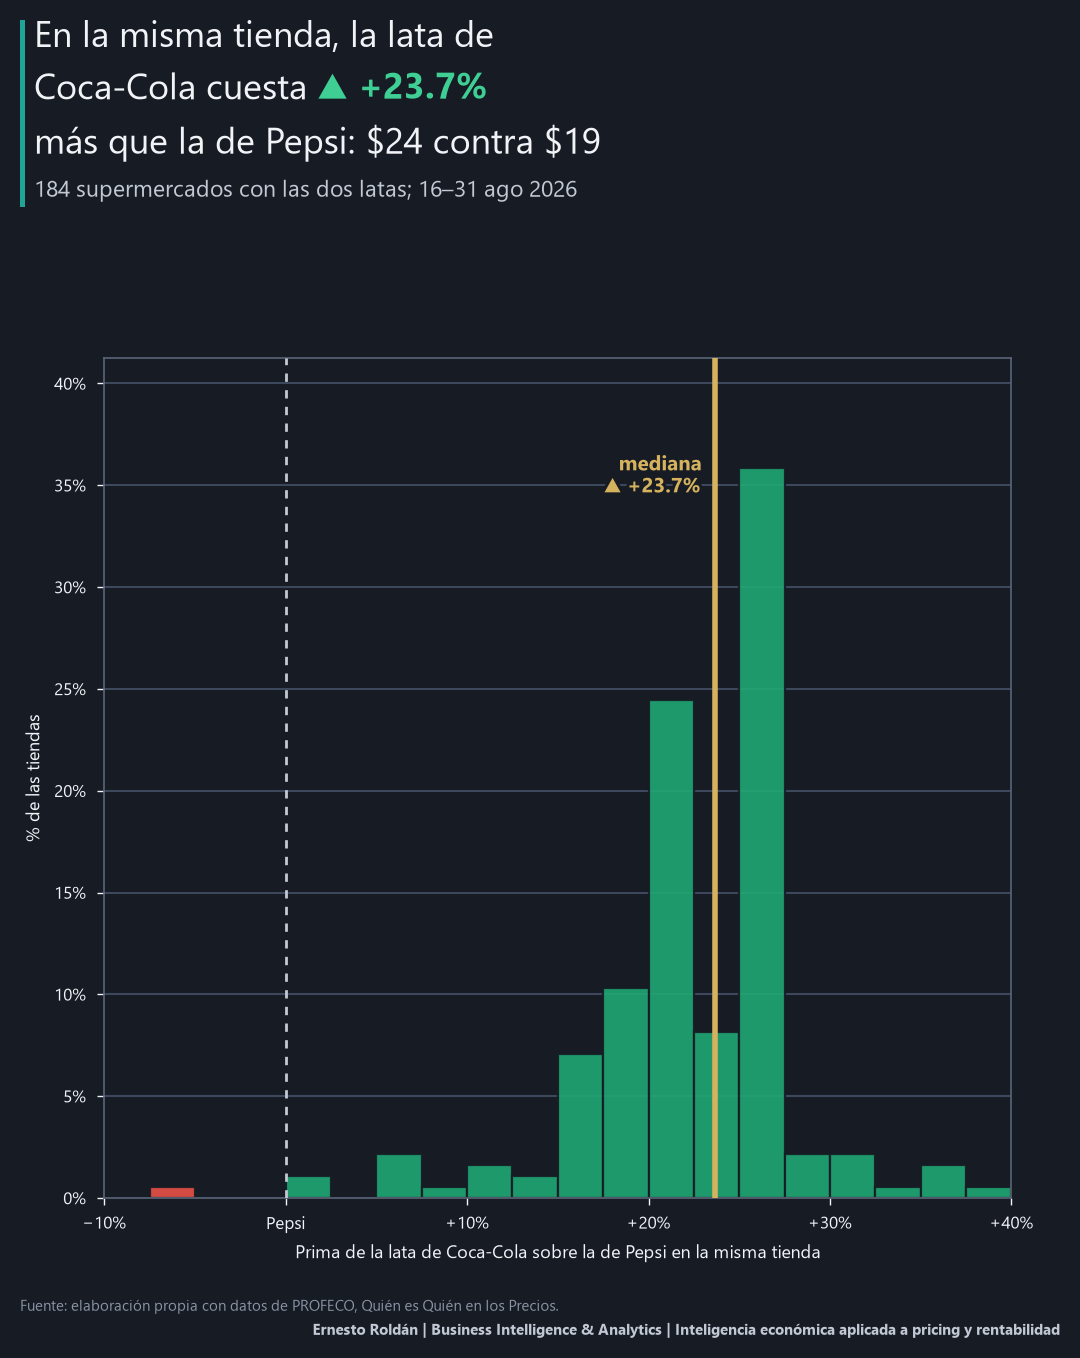

In [3]:
G.premium_social(pl, res, "horizontal", SOCIAL / "01_prima_lata_1280x720.png"); plt.show()
G.premium_social(pl, res, "vertical", SOCIAL / "01_prima_lata_1080x1350.png"); plt.show()

## Complementarias

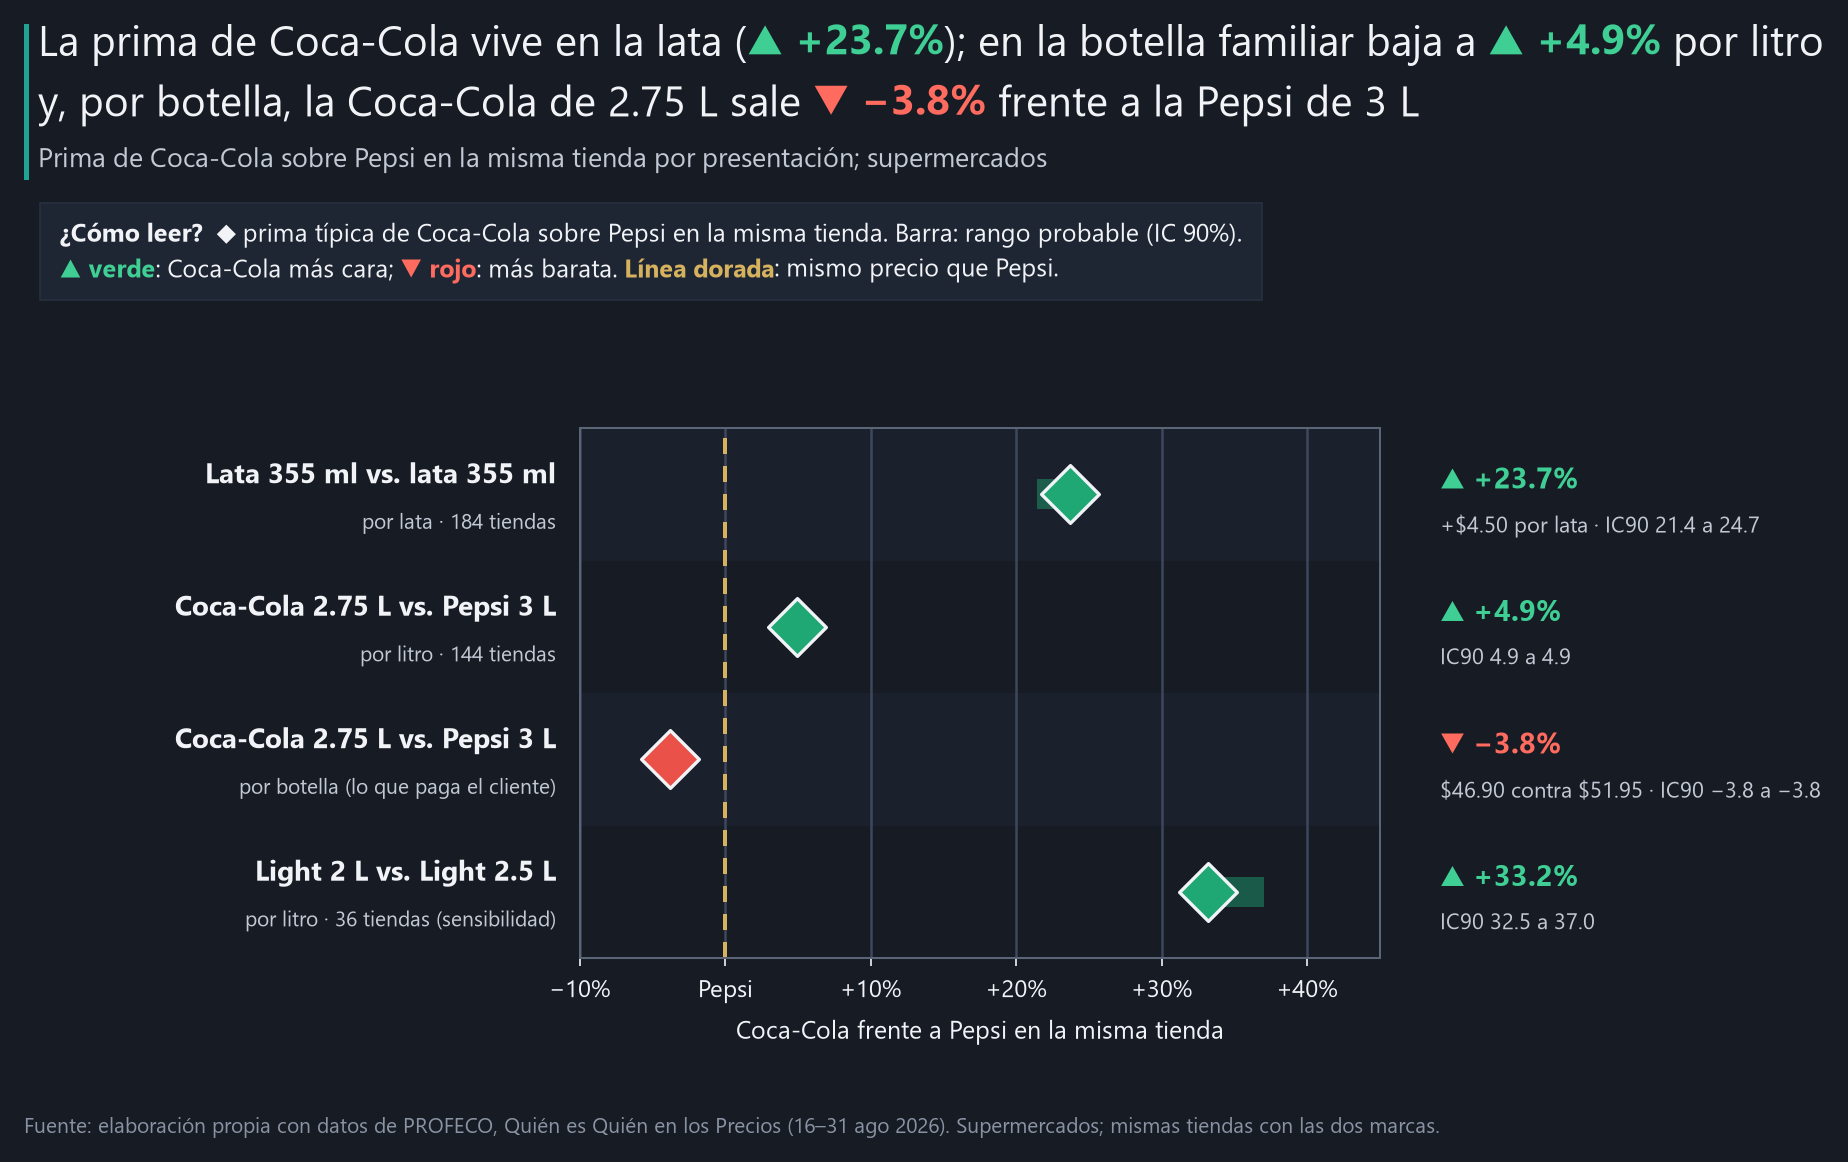

In [4]:
G.by_presentation(tt, res, CHARTS / "02_prima_por_presentacion.png"); plt.show()

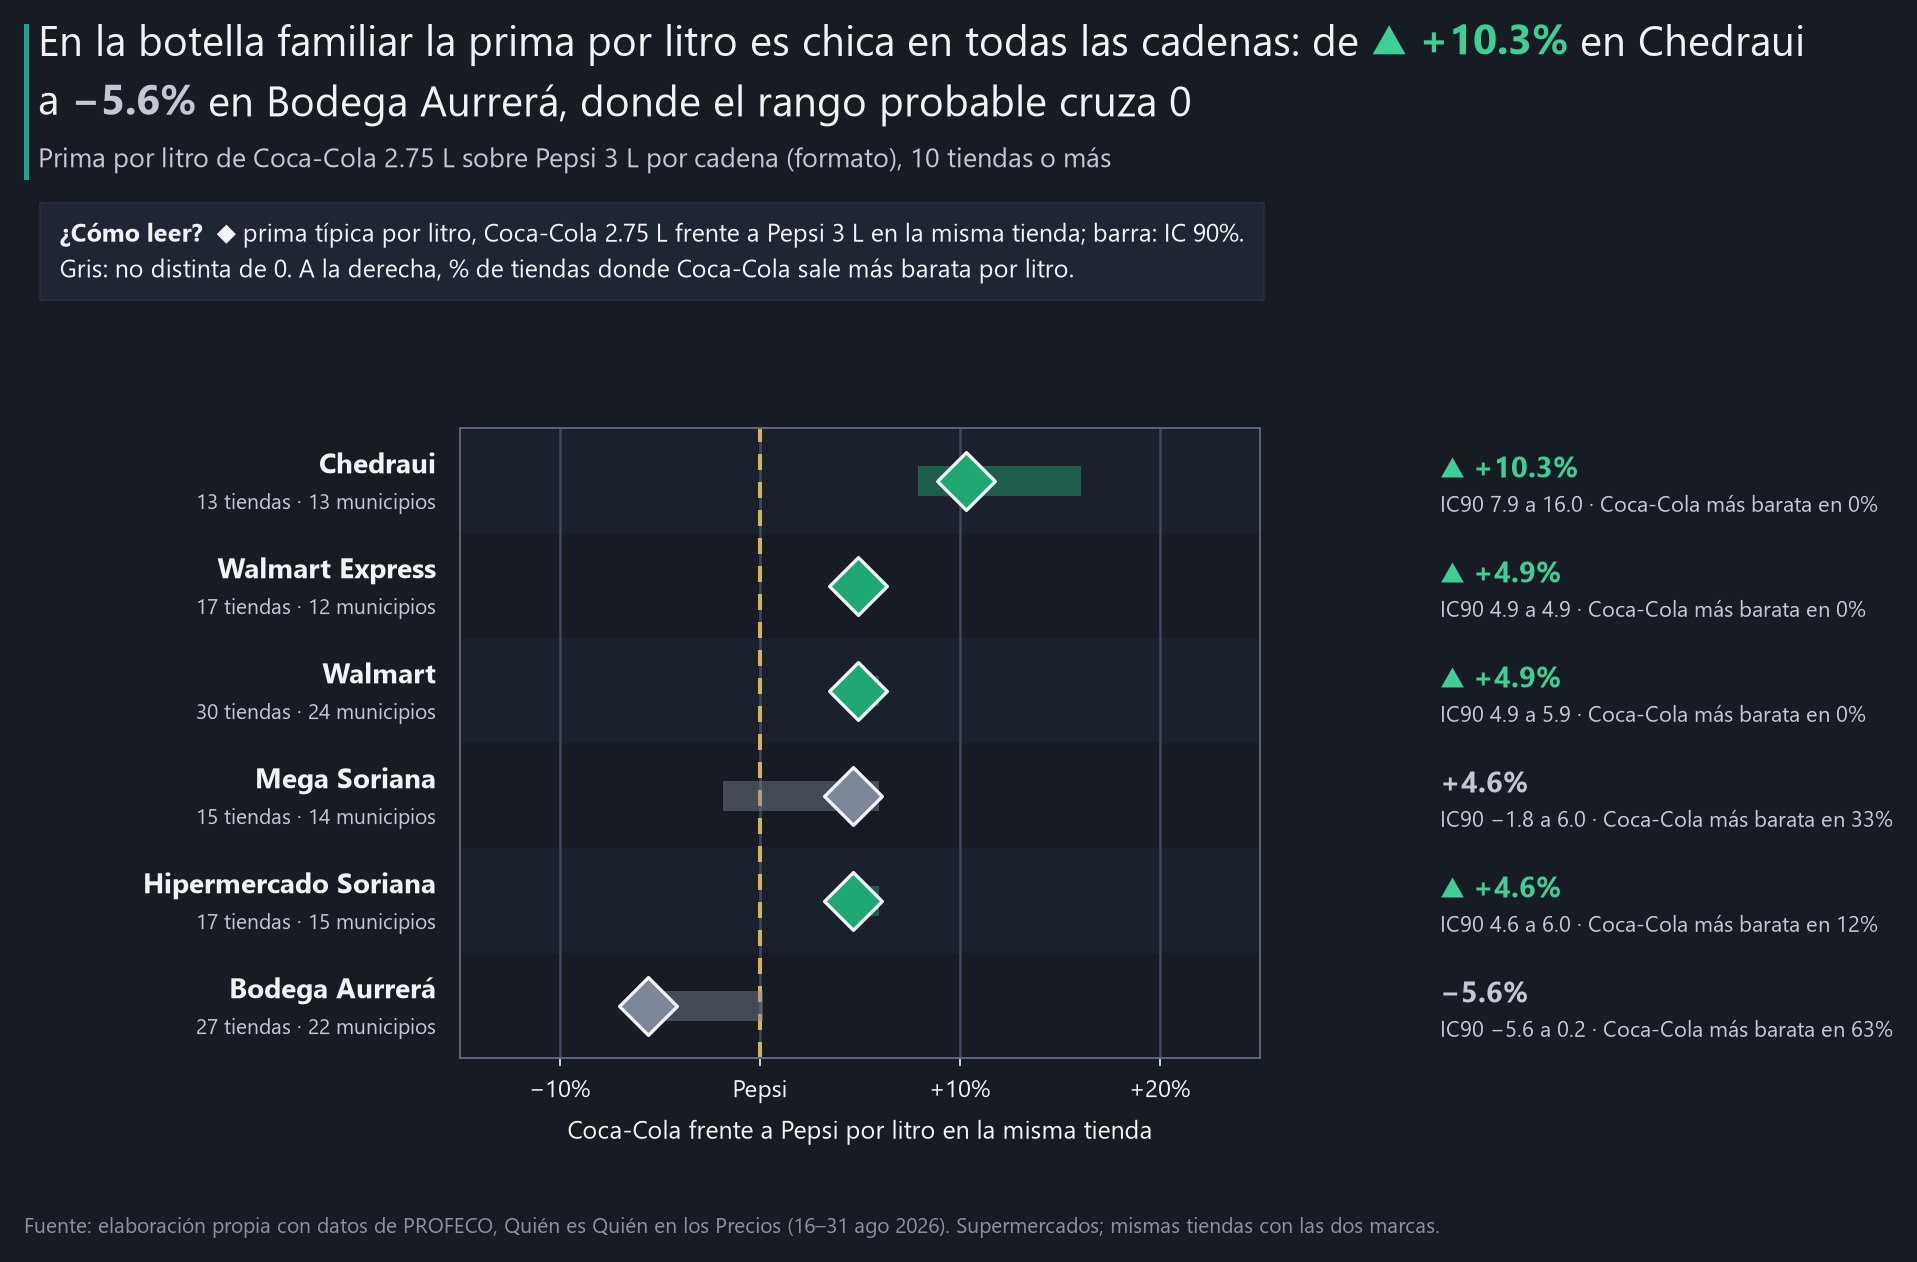

In [5]:
G.family_by_format(des, res, CHARTS / "03_familiar_por_formato.png"); plt.show()

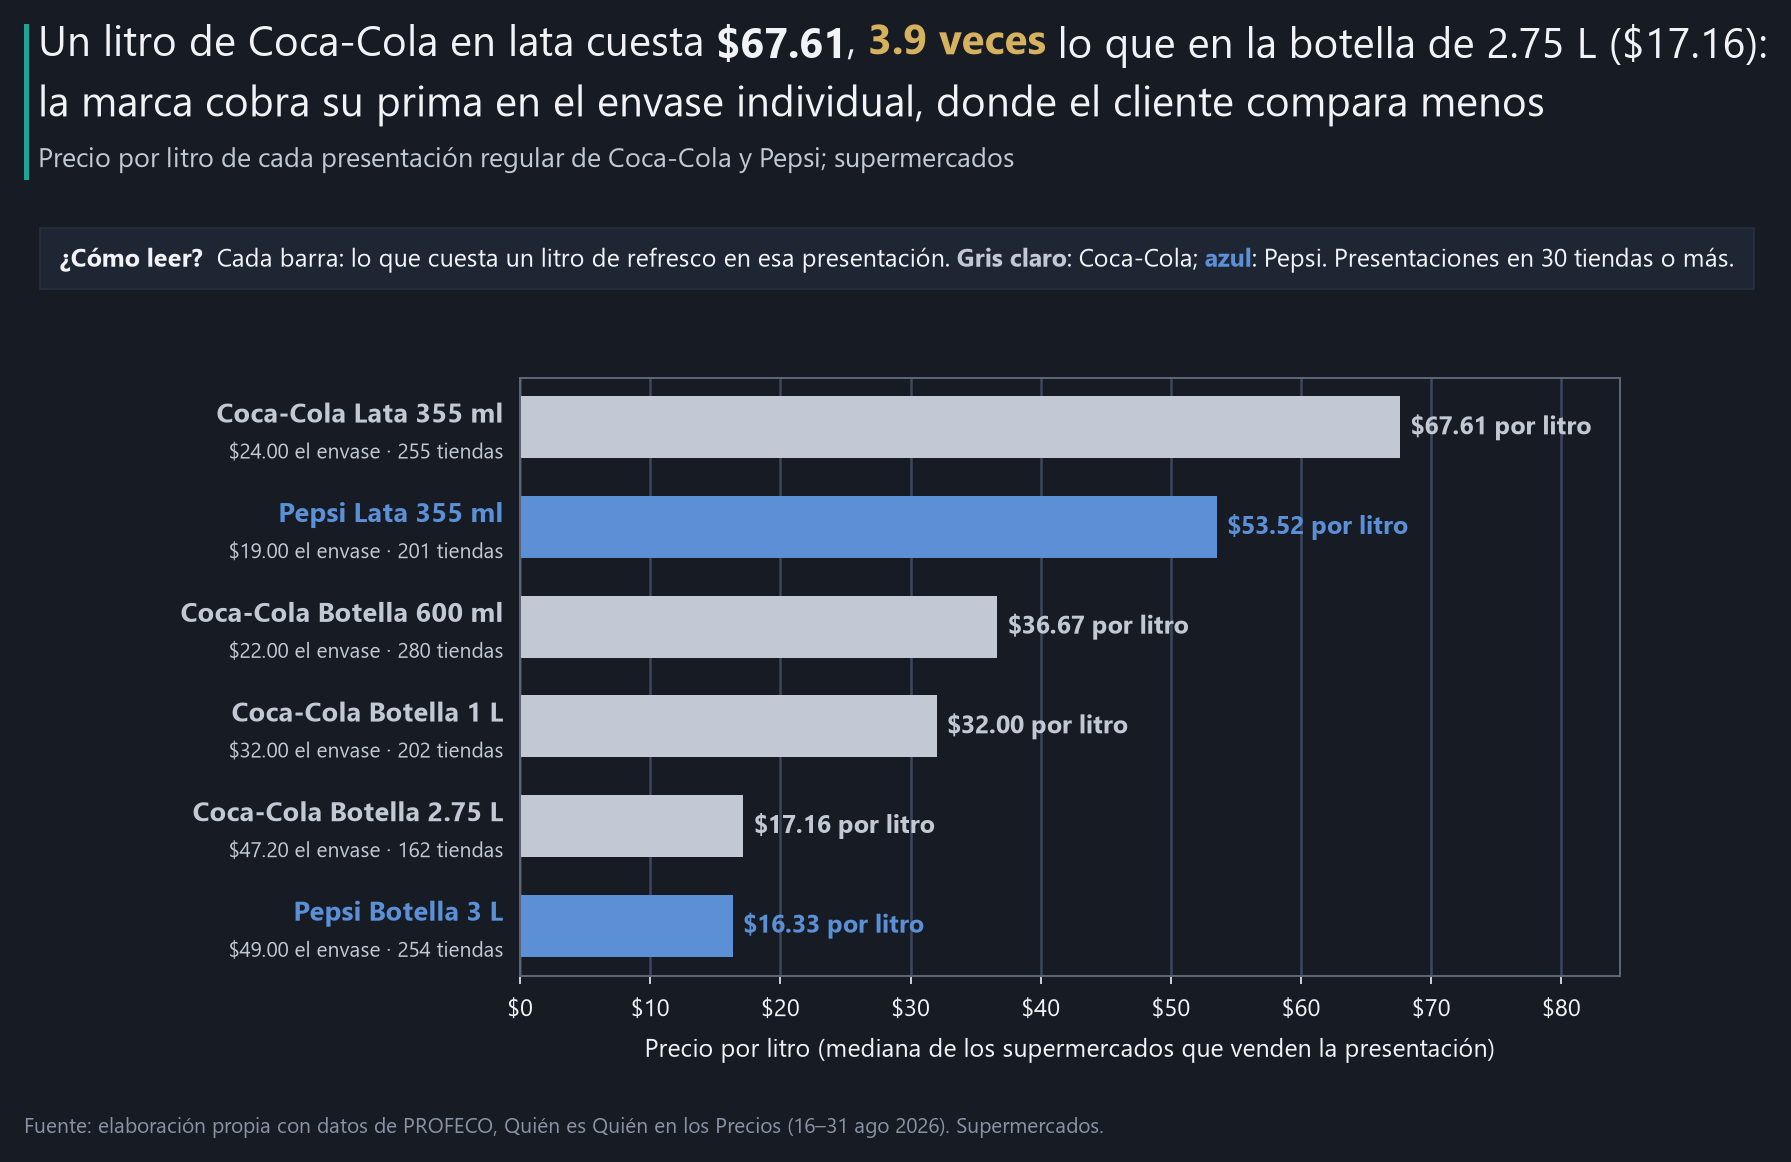

In [6]:
G.liter_ladder(lad, res, CHARTS / "04_precio_por_litro.png"); plt.show()

## Reporte HTML y README

In [7]:
GALERIA = [(g_["titulo"], g_["pie"], CHARTS / g_["archivo"]) for g_ in CFG["graficas"]]
out = reporte.build(pl, des, tt, res, CFG, GALERIA, ROOT / "docs/index.html")
print(out.relative_to(ROOT), f"{out.stat().st_size / 1e6:.1f} MB")
estructura = (ROOT / "src/estructura.md").read_text(encoding="utf-8")
(ROOT / "README.md").write_text(plantillas.readme(CFG, res, estructura), encoding="utf-8")
txt = (ROOT / "README.md").read_text(encoding="utf-8")
assert not re.search(r"\{[a-z][a-z0-9_]*(:[^}]*)?\}", txt), re.findall(r"\{[a-z][a-z0-9_]*(?::[^}]*)?\}", txt)[:5]
print("README actualizado")

docs\index.html 5.9 MB
README actualizado


## Qué hacer con esto

In [8]:
for aud, acc in CFG["readme"]["acciones"].items():
    display(Markdown(f"**{aud}**\n\n" + "\n".join(f"- {plantillas.render(a, res)}" for a in acc)))

**Dirección de marketing y ventas de la marca líder**

- **La prima se sostiene donde el cliente compra por impulso.** En la lata, 24% arriba de Pepsi y casi sin excepciones (1% de tiendas invertidas): ese es el activo de marca que hay que cuidar.
- **En el envase familiar la marca compite por precio de empaque.** La botella de 2.75 L cuesta menos que la Pepsi de 3 L en 79% de las tiendas. Si el objetivo es margen por litro, ahí está el espacio; si es volumen, la estrategia ya funciona.
- **Revise las cadenas con prima más baja en lata.** En Soriana la prima es 20% contra 26% en Bodega Aurrerá: la diferencia de anaquel la decide la cadena.

**Marca retadora**

- **No pelee la lata solo con precio.** Pepsi ya está $4.50 abajo en casi todas las tiendas y la líder sostiene su prima; la palanca está en visibilidad, frío y punto de venta.
- **Compita en el formato familiar con precio por litro visible.** Ahí la diferencia por litro es de 5% y el cliente compara empaques de tamaños distintos: hacer visible el precio por litro favorece a la botella de 3 L.
- **Busque presentaciones donde la líder no tiene par.** Coca-Cola de 600 ml no tiene competidor directo de Pepsi en el archivo.

**Dueño de tienda o cadena**

- **Use la lata para margen y la botella para tráfico.** El cliente acepta una prima de 24% en la lata de la líder; en el envase familiar compara precio por empaque.
- **Muestre el precio por litro.** Con envases de 2.75 L y 3 L, el precio por botella engaña; la etiqueta por litro ayuda al cliente y reduce reclamos.

**Analista comercial**

- **Compare en la misma tienda y en presentación equivalente.** El promedio nacional de cada marca mezcla tiendas, ciudades y tamaños.
- **Con tamaños distintos, reporte por litro y por empaque.** Por litro Coca-Cola sale 4.9% más cara; por botella, −3.8%: las dos lecturas son ciertas y dicen cosas distintas.